In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import(
    precision_score,
    f1_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [3]:
# Step 2: Load Dataset

df = pd.read_csv("breast-cancer.csv")
print("first 5 rows:",df.head())
print("dataset shape:",df.shape)
print("column namess:",df.columns)

# Step 3: Handle Missing Values
print("handling missing values:")
print(df.isnull().sum())
df.dropna()

# Step 4: Separate Features and Target
X=df.drop("diagnosis",axis = 1)
y=df["diagnosis"]


first 5 rows:          id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  perimeter_w

In [4]:
# Step 5: Convert Target into Numerical Values

# Assuming:
# M = Malignant
# B = Benign
y = y.map({
    "M": 1,
    "B": 0     
})
print("\n Target Classes")
print(y.value_counts())


 Target Classes
diagnosis
0    357
1    212
Name: count, dtype: int64


In [5]:
# Step 6: Split Dataset
X_train,X_test,y_train,y_test =train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Step 7: Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [6]:
# Step 8: Train Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled,y_train)
print("\nModel Training Completed!")



Model Training Completed!


In [7]:
# Step 9: Make Predictions
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]
# Step 10: Calculate Metrics
precision =precision_score(y_test, y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
print("\nModel Evaluation:")
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)



Model Evaluation:
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219



Confusion Matrix
[[71  1]
 [ 3 39]]


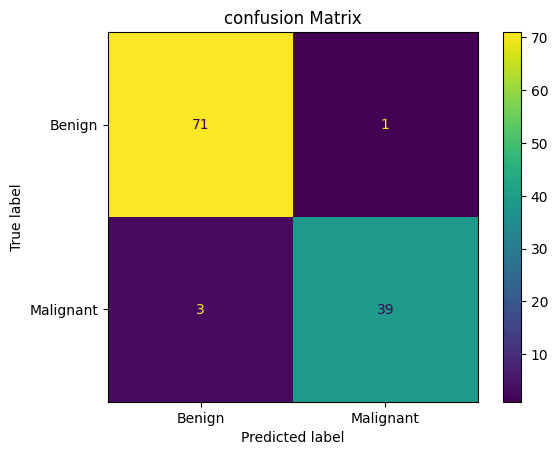

In [8]:
# Step 11: Generate Confusion Matrix
cm = confusion_matrix(y_test,y_pred)
print("\nConfusion Matrix")
print(cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)
disp.plot()
plt.title("confusion Matrix")
plt.show()

In [9]:
# Step 12: Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign","malignant"]
    )
)


Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [10]:
# Step 13: Experiment with Different Thresholds
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
print("\nThreshold Experiment:")
for threshold in thresholds:
    y_threshold_pred = (y_prob >= threshold).astype(int)
    precision = precision_score(
        y_test,
        y_threshold_pred,
        zero_division=0
    )
    recall_score(
        y_test,
        y_threshold_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_threshold_pred,
        zero_division=0
    )
    print(
        f"Threshold:{threshold:.1f} |"
        f"Presision:{precision:.3f} |"
        f"Recall:{recall:.3f} |"   
        f"f1:{f1:.3f}"
    )


Threshold Experiment:
Threshold:0.2 |Presision:0.932 |Recall:0.929 |f1:0.953
Threshold:0.3 |Presision:0.976 |Recall:0.929 |f1:0.976
Threshold:0.4 |Presision:0.976 |Recall:0.929 |f1:0.964
Threshold:0.5 |Presision:0.975 |Recall:0.929 |f1:0.951
Threshold:0.6 |Presision:1.000 |Recall:0.929 |f1:0.950
Threshold:0.7 |Presision:1.000 |Recall:0.929 |f1:0.950
Threshold:0.8 |Presision:1.000 |Recall:0.929 |f1:0.923


Precesion: [np.float64(0.9318181818181818), np.float64(0.9761904761904762), np.float64(0.975609756097561), np.float64(0.975), np.float64(1.0), np.float64(1.0), np.float64(1.0)] 
recalls: [np.float64(0.9761904761904762), np.float64(0.9761904761904762), np.float64(0.9523809523809523), np.float64(0.9285714285714286), np.float64(0.9047619047619048), np.float64(0.9047619047619048), np.float64(0.8571428571428571)] 
f1_scores [np.float64(0.9534883720930233), np.float64(0.9761904761904762), np.float64(0.963855421686747), np.float64(0.9512195121951219), np.float64(0.95), np.float64(0.95), np.float64(0.9230769230769231)]


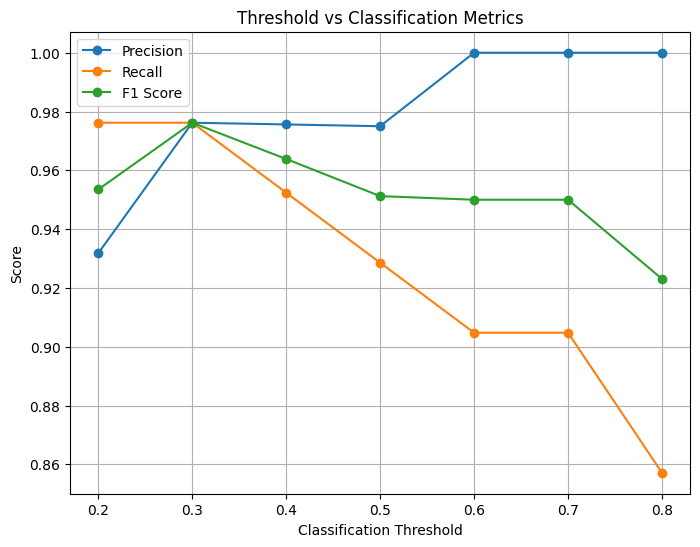

In [13]:
# Step 14: Plot Threshold Performance
precisions = []

recalls = []

f1_scores = []

for threshold in thresholds:

    y_threshold_pred = (y_prob >= threshold).astype(int)

    precisions.append(
        precision_score(
            y_test,
            y_threshold_pred,
            zero_division=0
        )
    )

    recalls.append(
        recall_score(
            y_test,
            y_threshold_pred,
            zero_division=0
        )
    )

    f1_scores.append(
        f1_score(
            y_test,
            y_threshold_pred,
            zero_division=0
        )
    )

print("Precesion:",precisions,"\nrecalls:",recalls,"\nf1_scores",f1_scores)
plt.figure(figsize=(8, 6))

plt.plot(thresholds, precisions, marker="o", label="Precision")

plt.plot(thresholds, recalls, marker="o", label="Recall")

plt.plot(thresholds, f1_scores, marker="o", label="F1 Score")

plt.xlabel("Classification Threshold")

plt.ylabel("Score")

plt.title("Threshold vs Classification Metrics")

plt.legend()

plt.grid()

plt.show()